# Assignment 3 — Nhiệm vụ A (Chương 9: hồi quy tuyến tính)

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from fractions import Fraction
from sklearn.linear_model import LinearRegression      
np.random.seed(42)                                       
pd.set_option('display.precision', 4)
df = pd.read_csv('bezdekIris.data', header=None, names=['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species'])
x = df['petal_length'].to_numpy()          # đầu vào  (N,)
y = df['sepal_length'].to_numpy()          # mục tiêu (N,)
N = len(x)
print('N =', N, '| x:', x.shape, '| y:', y.shape)
df[['petal_length', 'sepal_length']].head()

N = 150 | x: (150,) | y: (150,)


,petal_length,sepal_length
0,1.4,5.1
1,1.4,4.9
2,1.3,4.7
3,1.5,4.6
4,1.4,5.0


## A1 — Mô hình
$$y_n=\phi(x_n)^\top\theta+\varepsilon_n,\quad \varepsilon_n\sim\mathcal N(0,\sigma^2)\ \text{độc lập},\qquad p(y_n\mid x_n,\theta)=\mathcal N\big(y_n\mid\phi(x_n)^\top\theta,\sigma^2\big),\quad \theta=(\theta_0,\theta_1)^\top .$$
Giả thiết về nhiễu: (i) kỳ vọng 0; (ii) phương sai không đổi $\sigma^2$; (iii) phân phối Gauss; (iv) các nhiễu độc lập, nên $p(y\mid X,\theta)=\prod_n p(y_n\mid x_n,\theta)$; đầu vào $x_n$ được coi là hằng số đã biết.

In [ ]:
Phi = np.c_[np.ones(N), x]
print('Phi:', Phi.shape, '| Phi^T Phi:', (Phi.T @ Phi).shape, '| Phi^T y:', (Phi.T @ y).shape)

Phi: (150, 2) | Phi^T Phi: (2, 2) | Phi^T y: (2,)


## A2 — Cực đại hợp lý ⇒ bình phương tối thiểu ⇒ $\theta_{ML}$
Trong báo cáo: $\log p=-\frac N2\log(2\pi\sigma^2)-\frac1{2\sigma^2}\|y-\Phi\theta\|^2$, nên cực đại hợp lý ⇔ cực tiểu $\|y-\Phi\theta\|^2$.
Gradient (vectơ hàng) $\partial\mathcal L/\partial\theta=-2(y-\Phi\theta)^\top\Phi$; cho bằng 0 được phương trình chuẩn tắc $\Phi^\top\Phi\,\theta=\Phi^\top y$.
Dưới đây kiểm tra **bằng số**: gradient giải tích khớp vi phân sai phân hữu hạn, Hesse $2\Phi^\top\Phi$ xác định dương, và gradient triệt tiêu tại $\theta_{ML}$.

In [ ]:
def sse(th): return np.sum((y - Phi @ th) ** 2)                       
def grad_analytic(th): return -2 * (y - Phi @ th) @ Phi               

rng = np.random.default_rng(42)
th_test = rng.normal(size=2); eps = 1e-6
grad_fd = np.array([(sse(th_test + eps * e) - sse(th_test - eps * e)) / (2 * eps) for e in np.eye(2)])
print('gradient giải tích :', grad_analytic(th_test))
print('gradient sai phân  :', grad_fd, '| sai khác tương đối: %.2e' % (np.abs(grad_analytic(th_test) - grad_fd).max() / np.abs(grad_fd).max()))

theta_ml = np.linalg.solve(Phi.T @ Phi, Phi.T @ y)                    
print('theta_ML =', theta_ml, '| gradient tại theta_ML =', grad_analytic(theta_ml))
print('giá trị riêng của Hesse 2 Phi^T Phi:', np.linalg.eigvalsh(2 * Phi.T @ Phi), '-> xác định dương => L lồi, nghiệm duy nhất')

gradient giải tích : [ -2834.06295745 -11995.93666634]
gradient sai phân  : [ -2834.06295694 -11995.93666661] | sai khác tương đối: 4.28e-11
theta_ML = [4.30660342 0.40892228] | gradient tại theta_ML = [-8.17124146e-13 -2.87822538e-12]
giá trị riêng của Hesse 2 Phi^T Phi: [  51.45866823 5413.96133177] -> xác định dương => L lồi, nghiệm duy nhất


## A3 — Tính tay trên 5 mẫu đầu (đối chiếu bằng phân số chính xác)

In [ ]:
x5 = [Fraction(s) for s in ['1.4', '1.4', '1.3', '1.5', '1.4']]      
y5 = [Fraction(s) for s in ['5.1', '4.9', '4.7', '4.6', '5.0']]      
assert np.allclose([float(t) for t in x5], x[:5]) and np.allclose([float(t) for t in y5], y[:5])

Sx, Sxx = sum(x5), sum(t * t for t in x5)
Sy, Sxy = sum(y5), sum(a * b for a, b in zip(x5, y5))
print('Sum x =', float(Sx), '| Sum x^2 =', float(Sxx), '| Sum y =', float(Sy), '| Sum xy =', float(Sxy))
det = 5 * Sxx - Sx ** 2
print('Phi^T Phi = [[5, %s], [%s, %s]]  | det = %s' % (float(Sx), float(Sx), float(Sxx), float(det)))
th0 = (Sxx * Sy - Sx * Sxy) / det
th1 = (-Sx * Sy + 5 * Sxy) / det
print('theta_ML = (%s, %s)' % (float(th0), float(th1)))
fit = [th0 + th1 * t for t in x5]
res = [b - f for b, f in zip(y5, fit)]
print('giá trị khớp:', [float(f) for f in fit]); print('phần dư    :', [float(r) for r in res])
print('1^T r =', sum(res), '| x^T r =', sum(a * b for a, b in zip(x5, res)))

Sum x = 7.0 | Sum x^2 = 9.82 | Sum y = 24.3 | Sum xy = 34.01
Phi^T Phi = [[5, 7.0], [7.0, 9.82]]  | det = 0.1
theta_ML = (5.56, -0.5)
giá trị khớp: [4.86, 4.86, 4.91, 4.81, 4.86]
phần dư    : [0.24, 0.04, -0.21, -0.21, 0.14]
1^T r = 0 | x^T r = 0


In [ ]:
P5 = np.c_[np.ones(5), x[:5]]
th5 = np.linalg.solve(P5.T @ P5, P5.T @ y[:5]); r5 = y[:5] - P5 @ th5
print('theta_ML =', th5, '| Phi^T r =', P5.T @ r5, '(cỡ 1e-15: bằng 0 đến sai số làm tròn)')
print('cond(Phi^T Phi) = %.0f  -> gần suy biến vì 5 giá trị x gần như không đổi' % np.linalg.cond(P5.T @ P5))

theta_ML = [ 5.56 -0.5 ] | Phi^T r = [-1.77635684e-15  6.30473451e-15] (cỡ 1e-15: bằng 0 đến sai số làm tròn)
cond(Phi^T Phi) = 2194  -> gần suy biến vì 5 giá trị x gần như không đổi


## A4 — Hồi quy trên toàn bộ dữ liệu bằng công thức ở A2 (không dùng `LinearRegression`)

công thức nhóm: hệ số chặn 4.3066034150 | hệ số góc 0.4089222774
sklearn       : hệ số chặn 4.3066034150 | hệ số góc 0.4089222774
|sai khác hệ số chặn| = 3.55e-15 | |sai khác hệ số góc| = 5.55e-17 | max |sai khác dự đoán| = 3.55e-15
RMSE (cm): công thức nhóm 0.404352 | sklearn 0.404352


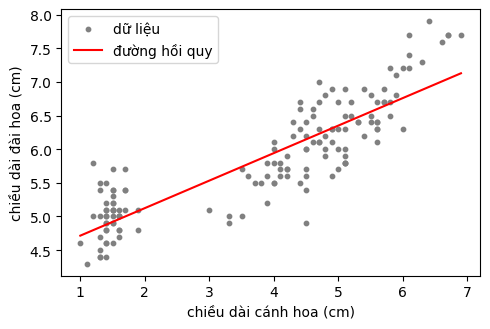

In [ ]:
def fit_ml(Phi, y):
    return np.linalg.solve(Phi.T @ Phi, Phi.T @ y)

theta = fit_ml(Phi, y)
lr = LinearRegression().fit(x[:, None], y)
pred, pred_sk = Phi @ theta, lr.predict(x[:, None])
print('công thức nhóm: hệ số chặn %.10f | hệ số góc %.10f' % tuple(theta))
print('sklearn       : hệ số chặn %.10f | hệ số góc %.10f' % (lr.intercept_, lr.coef_[0]))
print('|sai khác hệ số chặn| = %.2e | |sai khác hệ số góc| = %.2e | max |sai khác dự đoán| = %.2e'
      % (abs(theta[0] - lr.intercept_), abs(theta[1] - lr.coef_[0]), np.abs(pred - pred_sk).max()))
print('RMSE (cm): công thức nhóm %.6f | sklearn %.6f' % (np.sqrt(np.mean((y - pred) ** 2)), np.sqrt(np.mean((y - pred_sk) ** 2))))
plt.figure(figsize=(5, 3.4)); plt.scatter(x, y, s=10, c='gray', label='dữ liệu')
xs = np.linspace(x.min(), x.max(), 100); plt.plot(xs, theta[0] + theta[1] * xs, 'r', label='đường hồi quy')
plt.xlabel('chiều dài cánh hoa (cm)'); plt.ylabel('chiều dài đài hoa (cm)'); plt.legend(); plt.tight_layout(); plt.show()

## A5 — Ước lượng MAP
Với tiên nghiệm $\theta\sim\mathcal N(0,b^2I)$: $\;\theta_{MAP}=(\Phi^\top\Phi+\lambda I)^{-1}\Phi^\top y,\ \lambda=\sigma^2/b^2$ (chứng minh trong báo cáo).
Kiểm tra bằng số: (i) $\theta_{MAP}$ là cực tiểu của $\|y-\Phi\theta\|^2+\lambda\|\theta\|^2$; (ii) $\lambda\to0$ ($b\to\infty$) cho $\theta_{ML}$; (iii) $\lambda\to\infty$ ($b\to0$) cho $\theta\to0$ với cận $\|\theta_{MAP}\|\le\|\Phi^\top y\|/\lambda$.

In [ ]:
def fit_map(Phi, y, lam):
    return np.linalg.solve(Phi.T @ Phi + lam * np.eye(Phi.shape[1]), Phi.T @ y)

lam = 0.7; th_map = fit_map(P5, y[:5], lam)
grad_ridge = -2 * (y[:5] - P5 @ th_map) @ P5 + 2 * lam * th_map
print('(i) gradient Ridge tại theta_MAP =', grad_ridge)
rows = []
for lam in [0, 1e-8, 1e-4, 1e-2, 1, 1e2, 1e5, 1e8]:
    t = fit_map(P5, y[:5], lam)
    bound = np.linalg.norm(P5.T @ y[:5]) / lam if lam > 0 else np.inf
    rows.append([lam, t[0], t[1], np.linalg.norm(t), bound])
pd.DataFrame(rows, columns=['lambda = sigma2/b2', 'theta0', 'theta1', '||theta||', 'cận ||Phi^T y||/lambda'])

(i) gradient Ridge tại theta_MAP = [-5.77315973e-15 -4.44089210e-16]


,lambda = sigma2/b2,theta0,theta1,||theta||,cận ||Phi^T y||/lambda
0,0.0000e+00,5.5600e+00,-5.0000e-01,5.5824e+00,inf
1,1.0000e-08,5.5600e+00,-5.0000e-01,5.5824e+00,4.1799e+09
2,1.0000e-04,5.5027e+00,-4.5918e-01,5.5219e+00,4.1799e+05
3,1.0000e-02,3.2179e+00,1.1683e+00,3.4234e+00,4.1799e+03
4,1.0000e+00,1.5613e+00,2.1332e+00,2.6435e+00,4.1799e+01
5,1.0000e+02,2.1168e-01,2.9620e-01,3.6406e-01,4.1799e-01
6,1.0000e+05,2.4296e-04,3.4005e-04,4.1793e-04,4.1799e-04
7,1.0000e+08,2.4300e-07,3.4010e-07,4.1799e-07,4.1799e-07


## A6 — Đa thức bậc 1–10, chia 70/30 và hiện tượng quá khớp
Xáo trộn rồi chia 70/30 với hạt giống cố định; **chuẩn hoá $x$ bằng thống kê của tập huấn luyện trước khi lấy luỹ thừa** (nếu không $\Phi^\top\Phi$ điều kiện rất xấu).

train/test = 105 / 45 | mean_tr = 3.900, std_tr = 1.715


,bậc d,RMSE huấn luyện (cm),RMSE kiểm tra (cm),cond(Phi^T Phi),||theta||
0,1,0.4020,0.4163,1.0000e+00,5.9305
1,2,0.3629,0.3581,1.0222e+01,5.7291
2,3,0.3596,0.3662,1.0068e+02,5.7618
3,4,0.3581,0.3750,3.6089e+02,5.7482
4,5,0.3528,0.3863,2.3871e+03,5.7347
5,6,0.3391,0.4149,1.9784e+04,6.0441
6,7,0.3364,0.3920,9.6189e+04,6.1467
7,8,0.3364,0.3919,6.2309e+05,6.1474
8,9,0.3350,0.4035,6.0936e+06,7.1547
9,10,0.3318,0.3963,5.1928e+07,8.4785


bậc có sai số kiểm tra nhỏ nhất:

 2 | quá khớp bắt đầu ở bậc: 3
sai số huấn luyện không tăng theo bậc: True


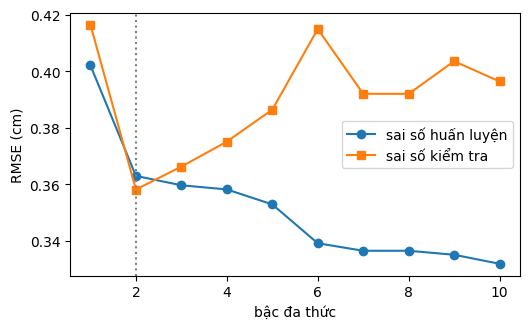

In [ ]:
rng = np.random.default_rng(42)
perm = rng.permutation(N); n_tr = int(0.7 * N)
tr, te = perm[:n_tr], perm[n_tr:]                      
m_tr, s_tr = x[tr].mean(), x[tr].std()
z = (x - m_tr) / s_tr                                  
print('train/test =', len(tr), '/', len(te), '| mean_tr = %.3f, std_tr = %.3f' % (m_tr, s_tr))
design = lambda z, d: np.vander(z, d + 1, increasing=True)     
rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))

res = []
for d in range(1, 11):
    P = design(z, d)
    th = fit_ml(P[tr], y[tr])
    res.append((d, rmse(P[tr] @ th, y[tr]), rmse(P[te] @ th, y[te]), np.linalg.cond(P[tr].T @ P[tr]), np.linalg.norm(th)))
R = pd.DataFrame(res, columns=['bậc d', 'RMSE huấn luyện (cm)', 'RMSE kiểm tra (cm)', 'cond(Phi^T Phi)', '||theta||'])
display(R)
best = int(R['RMSE kiểm tra (cm)'].idxmin()) + 1
onset = next(int(r.iloc[0]) for _, r in R.iterrows() if r.iloc[0] > best and r['RMSE kiểm tra (cm)'] > R['RMSE kiểm tra (cm)'].min())
print('bậc có sai số kiểm tra nhỏ nhất:', best, '| quá khớp bắt đầu ở bậc:', onset)
print('sai số huấn luyện không tăng theo bậc:', bool((np.diff(R['RMSE huấn luyện (cm)']) <= 1e-12).all()))
plt.figure(figsize=(5.4, 3.4))
plt.plot(R['bậc d'], R['RMSE huấn luyện (cm)'], 'o-', label='sai số huấn luyện')
plt.plot(R['bậc d'], R['RMSE kiểm tra (cm)'], 's-', label='sai số kiểm tra')
plt.axvline(best, ls=':', c='gray'); plt.xlabel('bậc đa thức'); plt.ylabel('RMSE (cm)'); plt.legend(); plt.tight_layout(); plt.show()

# MAI391 — Assignment 3 · Mission B (Chapter 10: Principal Component Analysis)

**Dataset:** Iris (`data/bezdekIris.data`, 150 samples × 4 features, all in cm)

### What goes where (read this first)
| Part | Must be solved by hand on paper (goes in the **report PDF**) | What this notebook does |
|---|---|---|
| **B1, B2** | **Yes** — three 3-D integer points, centring, the full $3\times3$ covariance $S$, symmetry, eigenvalues and first PC of the $2\times2$ block, percentage of variance kept. Missing hand work = zero for the item. | Gives a worked **example with exact fractions** and then *checks* it with numpy. Change the points in one cell to check your own. Your paper solution is the deliverable, not this code. |
| B3–B6 | No (computational) | Full solutions with plots, tables and cross-checks. |

**Conventions used throughout (state them in your report):**
* Covariance divisor is **N** (course convention); this is also what makes $\lambda_d=\sigma_d^2/N$ in B5.
* PCA in B3–B6 is done on **standardised** data (zero mean, unit variance per feature, divisor $N$), as the assignment states. All standardised quantities are **dimensionless**; raw quantities are in cm.
* Random numbers (only used for a stability demo) use fixed seeds, so every result is reproducible.

## 0. Setup and data

In [1]:
import importlib.util, subprocess, sys
REQUIRED = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "sklearn": "scikit-learn"}
missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
print("Missing packages installed:", missing or "none")

Missing packages installed: none


In [ ]:
import math
from fractions import Fraction as F
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True, linewidth=120)
pd.set_option("display.precision", 6)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
SEED = 42

FEATURES = ["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)"]
DATA_FILE = Path("iris/bezdekIris.data")
if DATA_FILE.exists():
    df = pd.read_csv(DATA_FILE, header=None, names=FEATURES + ["species"]).dropna()
else:  
    from sklearn.datasets import load_iris
    ir = load_iris(as_frame=True)
    df = ir.frame.iloc[:, :4].copy(); df.columns = FEATURES
    df["species"] = ir.target_names[ir.target]
X_raw = df[FEATURES].to_numpy(float)
species = df["species"].to_numpy()
N, d = X_raw.shape
print(f"data matrix: {N} samples x {d} features")

data matrix: 150 samples x 4 features


## B1. Covariance matrix of three 3-D points (by hand)

**Problem.** Choose three 3-D points with small integer coordinates. Compute the mean vector, centre the data, build the full $3\times3$ covariance matrix $S$ and check that it is symmetric.

**Method (what to write on paper).**
1. Mean: $\bar x=\frac1N\sum_n x_n$ with $N=3$.
2. Centre: $\tilde x_n=x_n-\bar x$. **Check immediately** that $\sum_n\tilde x_n=0$.
3. Covariance (divisor $N$): $S=\frac1N\sum_n\tilde x_n\tilde x_n^\top$, i.e. $S_{jk}=\frac1N\sum_n\tilde x_{nj}\tilde x_{nk}$.
4. Symmetry: $S_{jk}=S_{kj}$ because $\tilde x_{nj}\tilde x_{nk}=\tilde x_{nk}\tilde x_{nj}$.

**Example points used below** (chosen so the numbers stay small): $x_1=(5,3,4)$, $x_2=(2,0,5)$, $x_3=(2,3,3)$. Replace them in the next cell with your group's points to check your own paper solution.

In [ ]:
POINTS = [(5, 3, 4), (2, 0, 5), (2, 3, 3)]          
n3 = len(POINTS); dim = len(POINTS[0])

mean_f = [sum(F(p[j]) for p in POINTS) / n3 for j in range(dim)]
cent_f = [[F(p[j]) - mean_f[j] for j in range(dim)] for p in POINTS]
col_sums = [sum(c[j] for c in cent_f) for j in range(dim)]
S_f = [[sum(c[j] * c[k] for c in cent_f) / n3 for k in range(dim)] for j in range(dim)]

show = lambda q: str(q)
print("mean vector      :", [show(m) for m in mean_f])
print("centred points   :")
for i, c in enumerate(cent_f, 1):
    print(f"   x{i} - mean = ", [show(t) for t in c])
print("column sums of centred data (must be 0):", [show(t) for t in col_sums])
print("\nS = (1/N) * sum_n xc_n xc_n^T   (exact fractions)")
for row in S_f:
    print("   ", [show(t) for t in row])
print("\nS symmetric (exactly):", all(S_f[j][k] == S_f[k][j] for j in range(dim) for k in range(dim)))

S_np = np.cov(np.array(POINTS, float).T, bias=True)
S_toy = np.array([[float(t) for t in row] for row in S_f])
print("matches numpy np.cov(bias=True):", np.allclose(S_toy, S_np))
print("trace(S) = total variance =", show(sum(S_f[j][j] for j in range(dim))))

mean vector      : ['3', '2', '4']
centred points   :
   x1 - mean =  ['2', '1', '0']
   x2 - mean =  ['-1', '-2', '1']
   x3 - mean =  ['-1', '1', '-1']
column sums of centred data (must be 0): ['0', '0', '0']

S = (1/N) * sum_n xc_n xc_n^T   (exact fractions)
    ['2', '1', '0']
    ['1', '2', '-1']
    ['0', '-1', '2/3']

S symmetric (exactly): True
matches numpy np.cov(bias=True): True
trace(S) = total variance = 14/3


**Remarks (with the example points).** The centred points are $(2,1,0)$, $(-1,-2,1)$, $(-1,1,-1)$ and their sum is zero in every coordinate, which is the quick sanity check the assignment asks for. Note that $S$ is $3\times3$ whatever the number of points; with only $N=3$ points the data span at most a 2-dimensional subspace after centring, so $S$ has rank at most $N-1=2$ and $\det S=0$ (one eigenvalue is exactly 0).

## B2. Eigenvalues and first principal component of the $2\times2$ block (by hand)

**Problem.** Take the upper-left $2\times2$ block of $S$, find its eigenvalues and the first principal component, and say what percentage of the total variance that component keeps.

**Method (what to write on paper).** For $A=\begin{pmatrix}a&b\\b&d\end{pmatrix}$:
1. Characteristic polynomial $\lambda^2-(a+d)\lambda+(ad-b^2)=0$.
2. $\lambda_{1,2}=\dfrac{(a+d)\pm\sqrt{(a-d)^2+4b^2}}{2}$ (the discriminant is $\ge0$ for a symmetric matrix, so the eigenvalues are real).
3. Eigenvector of $\lambda_1$: solve $(A-\lambda_1I)v=0$; a solution is $v\propto(b,\ \lambda_1-a)$. Normalise to length 1. This unit vector is the **first principal direction**.
4. Variance kept by PC1 $=\dfrac{\lambda_1}{\lambda_1+\lambda_2}=\dfrac{\lambda_1}{\operatorname{tr}A}$.

In [ ]:
a, b, dd = S_f[0][0], S_f[0][1], S_f[1][1]       
tr, det = a + dd, a * dd - b * b
disc = (a - dd) ** 2 + 4 * b * b                  
print(f"block = [[{a}, {b}], [{b}, {dd}]]")
print(f"trace = {tr},  det = {det}")
print(f"characteristic polynomial:  lambda^2 - ({tr}) lambda + ({det}) = 0")
print(f"discriminant = (a-d)^2 + 4b^2 = {disc}  ->  sqrt = {math.sqrt(disc):.6f}")

lam1 = (float(tr) + math.sqrt(disc)) / 2
lam2 = (float(tr) - math.sqrt(disc)) / 2
print(f"\nlambda_1 = {lam1:.6f},   lambda_2 = {lam2:.6f}")
print("check: sum = trace ->", math.isclose(lam1 + lam2, float(tr)), "| product = det ->", math.isclose(lam1 * lam2, float(det)))

v_raw = np.array([float(b), lam1 - float(a)]) if float(b) != 0 else (np.array([1.0, 0.0]) if float(a) >= float(dd) else np.array([0.0, 1.0]))
pc1 = v_raw / np.linalg.norm(v_raw)
if pc1.sum() < 0: pc1 = -pc1                      
print(f"\nunnormalised v = {v_raw},  ||v|| = {np.linalg.norm(v_raw):.6f}")
print("first principal component (unit length) =", pc1)
print("residual ||A v - lambda_1 v|| =", np.linalg.norm(np.array([[float(a), float(b)], [float(b), float(dd)]]) @ pc1 - lam1 * pc1))

kept = lam1 / (lam1 + lam2)
print(f"\nvariance kept by PC1 of the 2x2 block = lambda_1 / (lambda_1 + lambda_2) = {lam1:.4f} / {lam1 + lam2:.4f} = {kept:.2%}")
print(f"(relative to the TOTAL variance of the full 3x3 S, tr S = {float(sum(S_f[j][j] for j in range(dim))):.4f}: {lam1 / float(sum(S_f[j][j] for j in range(dim))):.2%})")

A = np.array([[float(a), float(b)], [float(b), float(dd)]])
w_np, V_np = np.linalg.eigh(A)
w_np, V_np = w_np[::-1], V_np[:, ::-1]
v_np = V_np[:, 0] if V_np[:, 0].sum() >= 0 else -V_np[:, 0]
print("\nnumpy eigh:  eigenvalues =", w_np, "| PC1 =", v_np)
print("max |hand - numpy| (eigenvalues):", np.abs(np.array([lam1, lam2]) - w_np).max(),
      "| (eigenvector):", np.abs(pc1 - v_np).max())

block = [[2, 1], [1, 2]]
trace = 4,  det = 3
characteristic polynomial:  lambda^2 - (4) lambda + (3) = 0
discriminant = (a-d)^2 + 4b^2 = 4  ->  sqrt = 2.000000

lambda_1 = 3.000000,   lambda_2 = 1.000000
check: sum = trace -> True | product = det -> True

unnormalised v = [1. 1.],  ||v|| = 1.414214
first principal component (unit length) = [0.707107 0.707107]
residual ||A v - lambda_1 v|| = 0.0

variance kept by PC1 of the 2x2 block = lambda_1 / (lambda_1 + lambda_2) = 3.0000 / 4.0000 = 75.00%
(relative to the TOTAL variance of the full 3x3 S, tr S = 4.6667: 64.29%)

numpy eigh:  eigenvalues = [3. 1.] | PC1 = [0.707107 0.707107]
max |hand - numpy| (eigenvalues): 0.0 | (eigenvector): 0.0


**Remarks (with the example points).** The block is $\begin{pmatrix}2&1\\1&2\end{pmatrix}$, so $\lambda^2-4\lambda+3=0$, $\lambda_1=3,\ \lambda_2=1$, and $(A-3I)v=0$ gives $v\propto(1,1)$, i.e. PC1 $=\frac1{\sqrt2}(1,1)$. The first component keeps $3/4=75\%$ of the variance of this $2\times2$ block. Geometrically the two features are positively correlated, so the direction of greatest spread is the diagonal.
* An eigenvector is only defined up to sign ($\pm v$); numpy may return $-v$. State your sign convention.
* Because the eigenvalues of a symmetric matrix are real and the eigenvectors orthogonal, PC2 is simply the unit vector perpendicular to PC1.

## B3. PCA of the standardised Iris data and the 90 % rule

**Problem.** Apply PCA to the standardised data, plot the cumulative explained variance versus the number of components, and find the smallest number $M$ of components that keeps at least 90 % of the variance.

**Decision.** `sklearn.decomposition.PCA` centres the data but does **not** rescale it. We standardise ourselves ($z=(x-\bar x)/s$, divisor $N$) because the four measurements have different spreads; without it the feature with the largest variance would dominate. For comparison we also show the unstandardised result at the end of this section, because the two answers differ.

**Method.** $Z$ is the $N\times d$ standardised matrix, $S=\frac1NZ^\top Z$ (equal to the correlation matrix). PCA = eigendecomposition $S=V\Lambda V^\top$ with $\lambda_1\ge\dots\ge\lambda_d$; the explained-variance ratio of component $j$ is $\lambda_j/\sum_i\lambda_i$.

column means of Z: [-0. -0. -0. -0.]
column variances of Z (divisor N): [1. 1. 1. 1.]

S equals the correlation matrix of the raw data: True

     eigenvalue lambda_j  explained variance ratio  cumulative ratio
PC1             2.918498                  0.729624          0.729624
PC2             0.914030                  0.228508          0.958132
PC3             0.146757                  0.036689          0.994821
PC4             0.020715                  0.005179          1.000000

sum of eigenvalues = 4.000000  (= trace S = 4 = number of standardised features)
==> smallest number of components keeping >= 90 % of the variance: M = 2  (keeps 95.81%)


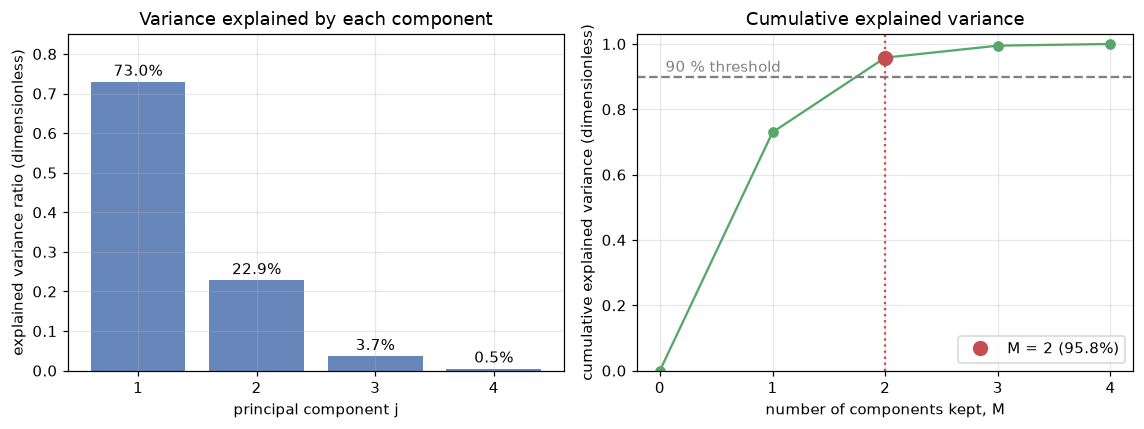

In [ ]:
mean_vec = X_raw.mean(axis=0)
std_vec = X_raw.std(axis=0, ddof=0)               
Z = (X_raw - mean_vec) / std_vec                  

print("column means of Z:", Z.mean(axis=0).round(12))
print("column variances of Z (divisor N):", Z.var(axis=0))

S = Z.T @ Z / N                                   
print("\nS equals the correlation matrix of the raw data:", np.allclose(S, np.corrcoef(X_raw.T)))

def fix_sign(v):                                  
    return v if v.sum() >= 0 else -v

w, V = np.linalg.eigh(S)
order = np.argsort(w)[::-1]
lam, V = w[order], V[:, order]
V = np.column_stack([fix_sign(V[:, j]) for j in range(d)])

ratio = lam / lam.sum()
cum = np.cumsum(ratio)
M = int(np.argmax(cum >= 0.90 - 1e-12) + 1)       

tbl = pd.DataFrame({"eigenvalue lambda_j": lam, "explained variance ratio": ratio, "cumulative ratio": cum},
                   index=[f"PC{j}" for j in range(1, d + 1)])
print(); print(tbl)
print(f"\nsum of eigenvalues = {lam.sum():.6f}  (= trace S = {np.trace(S):.0f} = number of standardised features)")
print(f"==> smallest number of components keeping >= 90 % of the variance: M = {M}  (keeps {cum[M - 1]:.2%})")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
idx = np.arange(1, d + 1)
axes[0].bar(idx, ratio, color="#4C72B0", alpha=.85)
for i, r in zip(idx, ratio): axes[0].annotate(f"{r:.1%}", (i, r), textcoords="offset points", xytext=(0, 4), ha="center")
axes[0].set_xticks(idx); axes[0].set_xlabel("principal component j"); axes[0].set_ylabel("explained variance ratio (dimensionless)")
axes[0].set_ylim(0, 0.85); axes[0].set_title("Variance explained by each component")
axes[1].plot([0, *idx], [0, *cum], "o-", color="#55A868")
axes[1].axhline(0.90, ls="--", color="grey"); axes[1].text(0.05, 0.915, "90 % threshold", color="grey")
axes[1].axvline(M, ls=":", color="#C44E52"); axes[1].plot([M], [cum[M - 1]], "o", color="#C44E52", ms=9, label=f"M = {M} ({cum[M - 1]:.1%})")
axes[1].set_xticks([0, *idx]); axes[1].set_ylim(0, 1.03)
axes[1].set_xlabel("number of components kept, M"); axes[1].set_ylabel("cumulative explained variance (dimensionless)")
axes[1].set_title("Cumulative explained variance"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=d, svd_solver="full").fit(Z)
print("explained-variance ratios agree with sklearn:", np.allclose(pca.explained_variance_ratio_, ratio))
print("sklearn explained_variance_ uses N-1; rescaled by (N-1)/N it equals our eigenvalues:",
      np.allclose(pca.explained_variance_ * (N - 1) / N, lam))
print("principal directions agree up to sign:",
      all(np.allclose(np.abs(pca.components_[j]), np.abs(V[:, j])) for j in range(d)))

Xc = X_raw - mean_vec
S_cm = Xc.T @ Xc / N                             
lam_cm = np.sort(np.linalg.eigvalsh(S_cm))[::-1]
cum_cm = np.cumsum(lam_cm / lam_cm.sum())
M_cm = int(np.argmax(cum_cm >= 0.90 - 1e-12) + 1)
cmp = pd.DataFrame({"standardised: cumulative ratio": cum, "centred only (cm): cumulative ratio": cum_cm},
                   index=[f"M={j}" for j in range(1, d + 1)])
print("\n", cmp)
print(f"minimum M for 90 %:  standardised -> {M},   centred only -> {M_cm}")
print("variances of the raw features (cm^2):", dict(zip([f.split(' (')[0] for f in FEATURES], X_raw.var(axis=0).round(3))))

explained-variance ratios agree with sklearn: True
sklearn explained_variance_ uses N-1; rescaled by (N-1)/N it equals our eigenvalues: True
principal directions agree up to sign: True

      standardised: cumulative ratio  centred only (cm): cumulative ratio
M=1                        0.729624                             0.924619
M=2                        0.958132                             0.977685
M=3                        0.994821                             0.994788
M=4                        1.000000                             1.000000
minimum M for 90 %:  standardised -> 2,   centred only -> 1
variances of the raw features (cm^2): {'sepal length': np.float64(0.681), 'sepal width': np.float64(0.189), 'petal length': np.float64(3.096), 'petal width': np.float64(0.577)}


**Remarks.**
* On standardised data **two components are needed** for 90 % (PC1 alone has about 73 %, PC1+PC2 about 96 %). So the four correlated measurements are essentially 2-dimensional.
* **Standardisation changes the answer.** If we only centre the data, petal length (variance about 3.1 cm²) dominates, one component already exceeds 90 %, and the "PC1" mostly reproduces petal length. That is why the assignment asks the group to state the choice: neither answer is "wrong", they answer different questions (variance in cm² versus variance relative to each feature's own spread).
* The eigenvalues sum to $\operatorname{tr}S=4$ because every standardised feature has variance 1, so $\lambda_j$ can be read as "how many features' worth of variance component $j$ carries" (PC1 carries about 2.9 of 4).

## B4. Projection onto the first two principal components

**Problem.** Project the data onto the first two components, draw the scatter plot, and comment on the visible structure.

**Method.** Scores $T=Z\,V_2$ where $V_2=[v_1\ v_2]$ (a $d\times2$ matrix with orthonormal columns). Species labels are used only to colour the points; PCA never saw them.

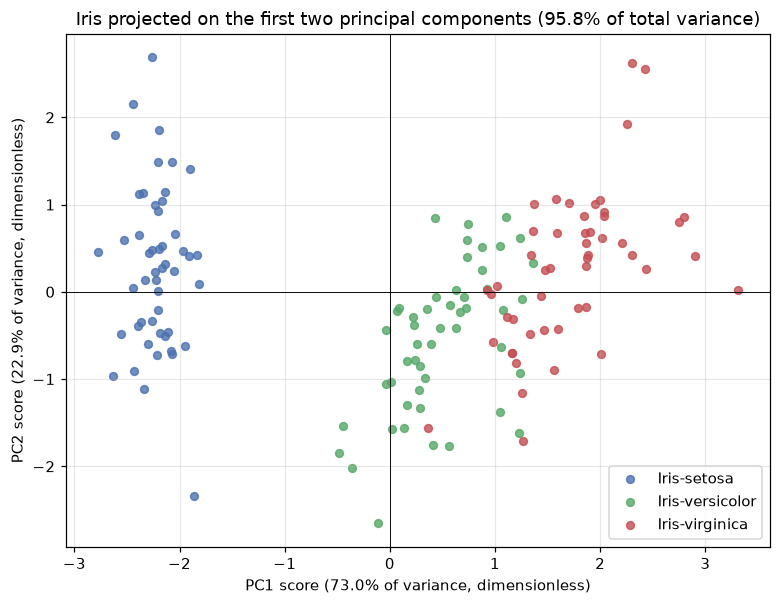

                   PC1 loading  PC2 loading
sepal length (cm)       0.5211       0.3774
sepal width (cm)       -0.2693       0.9233
petal length (cm)       0.5804       0.0245
petal width (cm)        0.5649       0.0669

scores are uncorrelated:  corr(PC1, PC2) = 0.0
variance of the scores (divisor N) equals lambda_1, lambda_2: [2.918498 0.91403 ] [2.918498 0.91403 ]

mean PC1 score by species:
                   mean    std
species                      
Iris-setosa     -2.225  0.206
Iris-versicolor  0.496  0.464
Iris-virginica   1.728  0.571


In [ ]:
T = Z @ V[:, :2]                                 

fig, ax = plt.subplots(figsize=(7.2, 5.6))
palette = {"Iris-setosa": "#4C72B0", "Iris-versicolor": "#55A868", "Iris-virginica": "#C44E52"}
for sp in pd.unique(species):
    m = species == sp
    ax.scatter(T[m, 0], T[m, 1], s=26, alpha=.8, color=palette.get(sp, "grey"), label=sp)
ax.axhline(0, color="k", lw=.6); ax.axvline(0, color="k", lw=.6)
ax.set_xlabel(f"PC1 score ({ratio[0]:.1%} of variance, dimensionless)")
ax.set_ylabel(f"PC2 score ({ratio[1]:.1%} of variance, dimensionless)")
ax.set_title(f"Iris projected on the first two principal components ({cum[1]:.1%} of total variance)")
ax.legend(); plt.tight_layout(); plt.show()

load = pd.DataFrame(V[:, :2], index=FEATURES, columns=["PC1 loading", "PC2 loading"])
print(load.round(4))
print("\nscores are uncorrelated:  corr(PC1, PC2) =", np.corrcoef(T[:, 0], T[:, 1])[0, 1].round(12))
print("variance of the scores (divisor N) equals lambda_1, lambda_2:", T.var(axis=0), lam[:2])
cent = pd.DataFrame(T, columns=["PC1", "PC2"]); cent["species"] = species
print("\nmean PC1 score by species:\n", cent.groupby("species")["PC1"].agg(["mean", "std"]).round(3))

**Remarks (visible structure).**
* **Setosa is cleanly separated** from the other two species along PC1 (far to the left, with a gap), even though PCA never used the labels. **Versicolor and virginica form two adjacent groups** along PC1 with a small overlap in the middle, so a 2-D picture shows the two-cluster plus one-overlap structure of Iris.
* PC1 loads with the same sign on sepal length, petal length and petal width and the opposite sign on sepal width: it is an overall **"flower size"** axis (petal measurements weigh the most). PC2 is dominated by sepal width and separates flowers of equal size by the width of the sepal.
* The two scores are exactly uncorrelated and their variances equal $\lambda_1,\lambda_2$, which confirms the eigen-analysis of B3.

## B5. PCA through the SVD, $\lambda_d=\sigma_d^2/N$, and numerical stability

**Problem.** Redo PCA through the SVD of the data matrix instead of diagonalising $S$; verify $\lambda_d=\sigma_d^2/N$; explain why the SVD route is numerically more stable.

**Derivation of the relation.** With $Z=U\Sigma V^\top$:
$$S=\tfrac1NZ^\top Z=\tfrac1N V\Sigma^\top U^\top U\Sigma V^\top=V\Big(\tfrac{\Sigma^2}{N}\Big)V^\top,$$
so the right singular vectors $V$ are the eigenvectors of $S$ and $\lambda_d=\sigma_d^2/N$.

In [ ]:
U, s, Vt = np.linalg.svd(Z, full_matrices=False)  

lam_svd = s ** 2 / N
print("singular values sigma_d :", s)
print("sigma_d^2 / N           :", lam_svd)
print("eigenvalues of S        :", lam)
print("max |sigma_d^2/N - lambda_d| =", np.abs(lam_svd - lam).max(), "->", np.allclose(lam_svd, lam))

V_svd = np.column_stack([fix_sign(Vt[j]) for j in range(d)])
print("directions agree up to sign:", np.allclose(np.abs(V_svd), np.abs(V)), "| max |difference| after sign fix:", np.abs(V_svd - V).max())

T_svd = U * s
print("scores: |Z V| equals |U Sigma|:", np.allclose(np.abs(Z @ V), np.abs(T_svd)))
print("variance ratio from SVD :", (s ** 2 / np.sum(s ** 2)).round(6), "| from eigenvalues:", ratio.round(6))
print("PCA via SVD gives the same M for 90 %:", int(np.argmax(np.cumsum(s ** 2 / np.sum(s ** 2)) >= 0.90 - 1e-12) + 1) == M)

singular values sigma_d : [20.923066 11.709166  4.691858  1.762732]
sigma_d^2 / N           : [2.918498 0.91403  0.146757 0.020715]
eigenvalues of S        : [2.918498 0.91403  0.146757 0.020715]
max |sigma_d^2/N - lambda_d| = 1.3322676295501878e-15 -> True
directions agree up to sign: True | max |difference| after sign fix: 1.7486012637846216e-15
scores: |Z V| equals |U Sigma|: True
variance ratio from SVD : [0.729624 0.228508 0.036689 0.005179] | from eigenvalues: [0.729624 0.228508 0.036689 0.005179]
PCA via SVD gives the same M for 90 %: True


### Why the SVD route is numerically more stable

Forming $S=\frac1NZ^\top Z$ **squares the condition number**: $\kappa(Z^\top Z)=\kappa(Z)^2$ (the singular values of $Z^\top Z$ are $\sigma_j^2$). Small singular values are therefore *squared*, and once $\sigma_j^2$ falls below $\varepsilon_{\text{mach}}\,\sigma_1^2\approx10^{-16}\sigma_1^2$, the information about that direction is **rounded away when $Z^\top Z$ is stored**, before any eigen-solver runs. The SVD works on $Z$ itself and keeps singular values accurate down to about $\varepsilon_{\text{mach}}\,\sigma_1$ (not $\sigma_1^2$). The demonstration below uses the classic Läuchli matrix.

In [ ]:
print(f"Iris: cond(Z) = {np.linalg.cond(Z):.2f},  cond(Z^T Z) = {np.linalg.cond(Z.T @ Z):.2f}  (= cond(Z)^2 = {np.linalg.cond(Z) ** 2:.2f})")

eps = 1e-9
A = np.array([[1, 1, 1], [eps, 0, 0], [0, eps, 0], [0, 0, eps]])
sv_true = np.array([math.sqrt(3 + eps ** 2), eps, eps])

sv_svd = np.linalg.svd(A, compute_uv=False)                        
gram = A.T @ A                                                      
ev = np.sort(np.linalg.eigvalsh(gram))[::-1]
sv_gram = np.sqrt(np.clip(ev, 0, None))

res = pd.DataFrame({"true": sv_true, "via SVD of A": sv_svd, "via eigenvalues of A^T A": sv_gram,
                    "rel. error SVD": np.abs(sv_svd - sv_true) / sv_true,
                    "rel. error A^T A": np.abs(sv_gram - sv_true) / sv_true},
                   index=["sigma_1", "sigma_2", "sigma_3"])
print(f"\nLauchli matrix with eps = {eps:g}   (cond(A) = {np.linalg.cond(A):.1e},  cond(A^T A) = {np.linalg.cond(gram):.1e})")
print("A^T A as stored in floating point (eps^2 = 1e-18 was added to 1 and vanished):\n", gram)
print(res.to_string(float_format=lambda v: f"{v:.3e}"))

Iris: cond(Z) = 11.87,  cond(Z^T Z) = 140.89  (= cond(Z)^2 = 140.89)

Lauchli matrix with eps = 1e-09   (cond(A) = 1.7e+09,  cond(A^T A) = inf)
A^T A as stored in floating point (eps^2 = 1e-18 was added to 1 and vanished):
 [[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]
             true  via SVD of A  via eigenvalues of A^T A  rel. error SVD  rel. error A^T A
sigma_1 1.732e+00     1.732e+00                 1.732e+00       0.000e+00         0.000e+00
sigma_2 1.000e-09     1.000e-09                 2.703e-09       0.000e+00         1.703e+00
sigma_3 1.000e-09     1.000e-09                 0.000e+00       6.204e-16         1.000e+00


**Remarks.**
* On Iris the two routes agree to about $10^{-15}$ because $Z$ is well conditioned ($\kappa(Z)\approx12$, so $\kappa(Z^\top Z)\approx141$); both methods are fine here. The point of the check is the identity $\lambda_d=\sigma_d^2/N$ and the same principal directions up to sign.
* The Läuchli example shows what can go wrong with the covariance route: the tiny singular values $\sigma_2=\sigma_3=10^{-9}$ become $10^{-18}$ in $A^\top A$, below double-precision resolution next to the entries equal to 1, so $A^\top A$ is stored as the all-ones matrix and the two small singular values come out as 0 (a relative error of 100 %), while the SVD of $A$ recovers them with relative error about $10^{-16}$.
* Other advantages of the SVD route: no need to form $S$ (cheaper memory when $d$ is large), and the singular values are non-negative by construction, whereas a computed eigenvalue of $S$ can come out slightly negative.

## B6. Reconstruction with $M$ components and the discarded-eigenvalue identity

**Problem.** Reconstruct the data from $M$ components (with $M$ from B3), compute the average reconstruction error, and compare it with $\sum_{j>M}\lambda_j$.

**Theory.** With $V_M=[v_1\dots v_M]$ the reconstruction of a (centred, standardised) point is $\hat z_n=V_MV_M^\top z_n$, and the average squared error is
$$J_M=\frac1N\sum_{n=1}^N\|z_n-\hat z_n\|^2=\sum_{j=M+1}^{d}\lambda_j .$$
*Why:* $z_n=\sum_{j}(v_j^\top z_n)v_j$, so $z_n-\hat z_n=\sum_{j>M}(v_j^\top z_n)v_j$ and, by orthonormality, $\|z_n-\hat z_n\|^2=\sum_{j>M}(v_j^\top z_n)^2$. Averaging over $n$ gives $v_j^\top Sv_j=\lambda_j$ for each $j$. In SVD language $\sum_n\|z_n-\hat z_n\|^2=\sum_{j>M}\sigma_j^2$ (the Eckart–Young error), and dividing by $N$ gives the same identity.

In [ ]:
def reconstruct(Zmat, Mkeep):
    VM = V[:, :Mkeep]
    return Zmat @ VM @ VM.T

rows = []
for Mk in range(0, d + 1):
    Zh = reconstruct(Z, Mk) if Mk > 0 else np.zeros_like(Z)
    err = np.mean(np.sum((Z - Zh) ** 2, axis=1))            
    dropped = lam[Mk:].sum()                               
    rows.append({"M": Mk, "mean reconstruction error J_M": err, "sum of discarded eigenvalues": dropped,
                 "|difference|": abs(err - dropped), "share of variance lost": dropped / lam.sum()})
rec = pd.DataFrame(rows).set_index("M")
print(rec.to_string(float_format=lambda v: f"{v:.6g}"))

Zh = reconstruct(Z, M)
J = np.mean(np.sum((Z - Zh) ** 2, axis=1))
print(f"\nFor M = {M} (from B3):  J_M = {J:.6f}   vs   sum_(j>{M}) lambda_j = {lam[M:].sum():.6f}   (discarded eigenvalues = {np.round(lam[M:], 6)})")
print("equal:", np.isclose(J, lam[M:].sum()), "| per-feature mean squared error =", np.round(((Z - Zh) ** 2).mean(axis=0), 4))
print("SVD form:  (1/N) sum_(j>M) sigma_j^2 =", (s[M:] ** 2).sum() / N, "| Frobenius check ||Z - Zhat||_F^2 / N =", np.linalg.norm(Z - Zh, "fro") ** 2 / N)

pca_M = PCA(n_components=M, svd_solver="full").fit(Z)
Zh_sk = pca_M.inverse_transform(pca_M.transform(Z))
print("matches sklearn inverse_transform:", np.allclose(Zh, Zh_sk))

   mean reconstruction error J_M  sum of discarded eigenvalues  |difference|  share of variance lost
M                                                                                                   
0                              4                             4   1.77636e-15                       1
1                         1.0815                        1.0815   1.55431e-15                0.270376
2                       0.167472                      0.167472   1.66533e-16               0.0418679
3                      0.0207148                     0.0207148   3.29597e-16              0.00517871
4                    1.56112e-30                             0   1.56112e-30                       0

For M = 2 (from B3):  J_M = 0.167472   vs   sum_(j>2) lambda_j = 0.167472   (discarded eigenvalues = [0.146757 0.020715])
equal: True | per-feature mean squared error = [0.0774 0.0091 0.0163 0.0647]
SVD form:  (1/N) sum_(j>M) sigma_j^2 = 0.16747171199993427 | Frobenius check ||Z - Zhat||_F^2

Reconstruction with M = 2 component(s), errors in original units:
                   feature std (cm)  MSE per feature (cm^2)  RMSE per feature (cm)  RMSE / std (dimensionless)
sepal length (cm)            0.8253                  0.0527                 0.2296                      0.2782
sepal width (cm)             0.4344                  0.0017                 0.0414                      0.0953
petal length (cm)            1.7594                  0.0504                 0.2244                      0.1276
petal width (cm)             0.7597                  0.0374                 0.1933                      0.2544

example: first 3 flowers  [original (cm)  ->  reconstructed (cm)]
   [5.1 3.5 1.4 0.2] -> [5.019 3.515 1.466 0.252]
   [4.9 3.  1.4 0.2] -> [4.738 3.03  1.604 0.272]
   [4.7 3.2 1.3 0.2] -> [4.72  3.197 1.329 0.167]


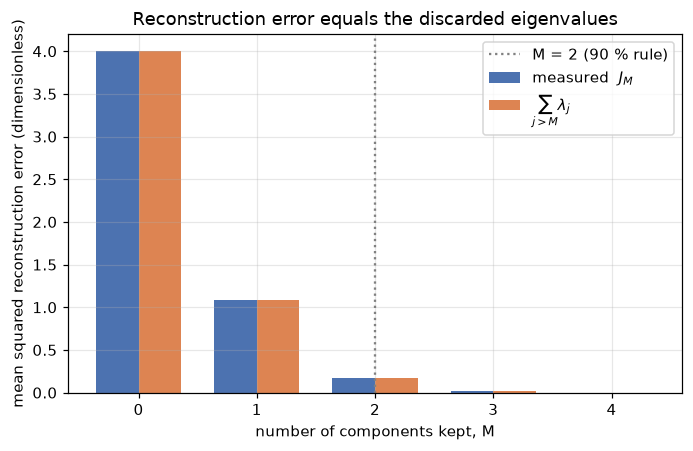

In [ ]:
X_hat = Zh * std_vec + mean_vec
err_cm2 = ((X_raw - X_hat) ** 2).mean(axis=0)
tbl_cm = pd.DataFrame({"feature std (cm)": std_vec, "MSE per feature (cm^2)": err_cm2,
                       "RMSE per feature (cm)": np.sqrt(err_cm2),
                       "RMSE / std (dimensionless)": np.sqrt(err_cm2) / std_vec}, index=FEATURES)
print(f"Reconstruction with M = {M} component(s), errors in original units:")
print(tbl_cm.round(4).to_string())
print("\nexample: first 3 flowers  [original (cm)  ->  reconstructed (cm)]")
for i in range(3):
    print("  ", X_raw[i], "->", X_hat[i].round(3))

fig, ax = plt.subplots(figsize=(6.4, 4.2))
Ms = rec.index.values
ax.bar(Ms - 0.18, rec["mean reconstruction error J_M"], width=0.36, color="#4C72B0", label="measured  $J_M$")
ax.bar(Ms + 0.18, rec["sum of discarded eigenvalues"], width=0.36, color="#DD8452", label=r"$\sum_{j>M}\lambda_j$")
ax.axvline(M, color="grey", ls=":", label=f"M = {M} (90 % rule)")
ax.set_xticks(Ms); ax.set_xlabel("number of components kept, M")
ax.set_ylabel("mean squared reconstruction error (dimensionless)")
ax.set_title("Reconstruction error equals the discarded eigenvalues"); ax.legend()
plt.tight_layout(); plt.show()

In [ ]:
Xt = np.array(POINTS, float); mt = Xt.mean(axis=0); Xtc = Xt - mt
wt, Vt_ = np.linalg.eigh(Xtc.T @ Xtc / len(Xt)); wt, Vt_ = wt[::-1], Vt_[:, ::-1]
Xh = Xtc @ Vt_[:, :1] @ Vt_[:, :1].T
Jt = np.mean(np.sum((Xtc - Xh) ** 2, axis=1))
print("toy example eigenvalues of S:", wt.round(6))
print(f"M = 1:  J = {Jt:.6f},   sum of discarded eigenvalues = {wt[1:].sum():.6f}")

toy example eigenvalues of S: [3.21525  1.451416 0.      ]
M = 1:  J = 1.451416,   sum of discarded eigenvalues = 1.451416


**Remarks.**
* With $M=2$ the mean squared reconstruction error is about **0.168** (standardised units, dimensionless): exactly $\lambda_3+\lambda_4=0.1468+0.0207$. It is also 4.2 % of the total variance (4), the complement of the 95.8 % kept in B3. The two columns of the table agree to machine precision for every $M$, which is the identity $J_M=\sum_{j>M}\lambda_j$.
* In cm, with two components the typical error is a few hundredths to a few tenths of a centimetre per feature (table above); relative to its own spread, **sepal width is reconstructed best** (RMSE about 0.10 of its std) because PC2 is made almost entirely of sepal width, whereas sepal length and petal width are reconstructed worst (about 0.25–0.28 of their std) because part of their variation lies in the discarded components PC3 and PC4.
* The identity also explains the PCA/least-squares equivalence: *maximising the variance kept* ($\sum_{j\le M}\lambda_j$) and *minimising the reconstruction error* ($\sum_{j>M}\lambda_j$) are the same problem because the two sums add up to the constant $\operatorname{tr}S$.

## Summary of Mission B results (for the report)

In [13]:
print("B1  (toy points)", POINTS, "-> mean", [str(m) for m in mean_f], "; S =", [[str(t) for t in r] for r in S_f])
print(f"B2  2x2 block eigenvalues: {lam1:.4f}, {lam2:.4f};  PC1 = {np.round(pc1, 4)};  variance kept = {kept:.1%}")
print(f"B3  standardised Iris: eigenvalues {lam.round(4)};  cumulative {cum.round(4)};  M for 90 % = {M}  (unstandardised would give M = {M_cm})")
print(f"B4  first two PCs keep {cum[1]:.1%}; setosa separates along PC1; PC1 loadings {V[:, 0].round(3)}")
print(f"B5  max |sigma^2/N - lambda| = {np.abs(lam_svd - lam).max():.1e};  Lauchli rel. error: A^T A route {res['rel. error A^T A'].max():.1e} vs SVD {res['rel. error SVD'].max():.1e}")
print(f"B6  M = {M}: J_M = {J:.6f} = sum of discarded eigenvalues = {lam[M:].sum():.6f}")

B1  (toy points) [(5, 3, 4), (2, 0, 5), (2, 3, 3)] -> mean ['3', '2', '4'] ; S = [['2', '1', '0'], ['1', '2', '-1'], ['0', '-1', '2/3']]
B2  2x2 block eigenvalues: 3.0000, 1.0000;  PC1 = [0.7071 0.7071];  variance kept = 75.0%
B3  standardised Iris: eigenvalues [2.9185 0.914  0.1468 0.0207];  cumulative [0.7296 0.9581 0.9948 1.    ];  M for 90 % = 2  (unstandardised would give M = 1)
B4  first two PCs keep 95.8%; setosa separates along PC1; PC1 loadings [ 0.521 -0.269  0.58   0.565]
B5  max |sigma^2/N - lambda| = 1.3e-15;  Lauchli rel. error: A^T A route 1.7e+00 vs SVD 6.2e-16
B6  M = 2: J_M = 0.167472 = sum of discarded eigenvalues = 0.167472


# Assignment 3 — Nhiệm vụ C: Phân loại bằng SVM

**MAI391 — Toán cho Học máy | Chương 12**  
Dữ liệu: Iris (tiếp nối Assignment 1).  

Nhiệm vụ C dùng hai đặc trưng liên tục + nhãn nhị phân tạo từ dữ liệu.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

DATA_PATH = Path("data/iris.data")
cols = ["sepal_length", "sepal_width", "petal_length", "petal_width", "class"]
df = pd.read_csv(DATA_PATH, header=None, names=cols)

print("Kích thước:", df.shape)
print(df.head())
print(df["class"].value_counts())

Kích thước: (150, 5)
   sepal_length  sepal_width  petal_length  petal_width        class
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa
class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


---
## C1. Tạo nhãn nhị phân và giữ hai đặc trưng

Chọn **petal length** và **petal width** (hai đặc trưng tách lớp tốt trên Iris).  
Nhãn nhị phân: $y = +1$ nếu `class == Iris-setosa`, $y = -1$ nếu không (versicolor + virginica).

Setosa tách tuyến tính rõ với hai lớp còn lại → phù hợp minh họa SVM tuyến tính.

In [2]:
X_raw = df[["petal_length", "petal_width"]].values.astype(float)

y = np.where(df["class"].values == "Iris-setosa", 1, -1)

scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

print("X shape:", X.shape)
print("Số mẫu +1 (Setosa):", np.sum(y == 1))
print("Số mẫu -1:", np.sum(y == -1))
print("X[:5] =")
print(X[:5])
print("y[:5] =", y[:5])

X shape: (150, 2)
Số mẫu +1 (Setosa): 50
Số mẫu -1: 100
X[:5] =
[[-1.3412724  -1.31297673]
 [-1.3412724  -1.31297673]
 [-1.39813811 -1.31297673]
 [-1.2844067  -1.31297673]
 [-1.3412724  -1.31297673]]
y[:5] = [1 1 1 1 1]


---
## C2. Làm tay: siêu phẳng lề cực đại cho 2 điểm

Cho:
- $x_1 = (1, 1)$, $y_1 = +1$
- $x_2 = (-1, -1)$, $y_2 = -1$

### Bước 1. Siêu phẳng dạng $w^\top x + b = 0$

Hai điểm đối xứng qua gốc → biên quyết định đi qua gốc ($b = 0$) và vuông góc với đường nối hai điểm.

Vector nối $x_1 - x_2 = (2, 2)$ cùng hướng pháp tuyến. Chọn
$$
w = \begin{bmatrix}1\\1\end{bmatrix}
$$
(hướng từ lớp −1 sang +1).

### Bước 2. Chuẩn hoá để điểm nằm trên lề

Điều kiện lề cứng: $y_n(w^\top x_n + b) \ge 1$, và đẳng thức tại support vector.

Với $b = 0$:
$$
y_1 w^\top x_1 = (+1)\,w^\top(1,1) = w_1 + w_2 = 1
$$
(tương tự điểm 2 cũng cho $w_1 + w_2 = 1$).

Vì $w$ song song $(1,1)$, đặt $w = t(1,1)$. Thì $2t = 1 \Rightarrow t = 1/2$.
$$
\boxed{w^* = \begin{bmatrix}1/2\\1/2\end{bmatrix},\quad b^* = 0}
$$

### Bước 3. Giá trị lề

$$
\text{margin} = \frac{2}{\|w\|} = \frac{2}{\sqrt{(1/2)^2+(1/2)^2}} = \frac{2}{\sqrt{1/2}} = \frac{2}{1/\sqrt{2}} = 2\sqrt{2}.
$$

### Bước 4. Vectơ hỗ trợ

Cả hai điểm thoả $y_n(w^\top x_n + b) = 1$ → **cả $x_1$ và $x_2$ đều là support vectors**.

### Kiểm chứng số

In [3]:
w_star = np.array([0.5, 0.5])
b_star = 0.0
x1 = np.array([1.0, 1.0])
x2 = np.array([-1.0, -1.0])

print("y1 (w·x1 + b) =", 1 * (w_star @ x1 + b_star))
print("y2 (w·x2 + b) =", -1 * (w_star @ x2 + b_star))
print("||w|| =", np.linalg.norm(w_star))
print("margin = 2/||w|| =", 2 / np.linalg.norm(w_star))
print("Support vectors: x1 và x2 (cả hai)")

y1 (w·x1 + b) = 1.0
y2 (w·x2 + b) = 1.0
||w|| = 0.7071067811865476
margin = 2/||w|| = 2.82842712474619
Support vectors: x1 và x2 (cả hai)


---
## C3. Vai trò hình học của $w$ và $b$

- **$w$ (pháp tuyến):** hướng của $w$ xác định hướng của biên quyết định.  
  Biên vuông góc với $w$. Đổi hướng $w$ (xoay) → biên xoay theo.  
  Độ lớn $\|w\|$ liên hệ nghịch với độ rộng lề: $\text{margin} = 2/\|w\|$.

- **$b$ (độ chệch):** dịch biên song song với chính nó.  
  Tăng $b$ → biên dịch về phía ngược hướng $w$; giảm $b$ → dịch theo hướng $w$.  
  Không làm thay đổi hướng hay độ rộng lề (khi $\|w\|$ cố định).

Tóm lại: $w$ điều khiển **hướng + độ rộng lề**; $b$ điều khiển **vị trí song song** của biên.

---
## C4. SVM tuyến tính với $C \in \{0.01, 1, 100\}$

Huấn luyện trên dữ liệu C1. Vẽ biên ($w^\top x + b = 0$) và hai đường lề ($= \pm 1$).

- $C$ nhỏ → cho phép nhiều vi phạm lề, lề rộng (ưu tiên margin lớn).
- $C$ lớn → ít vi phạm, lề hẹp hơn (ưu tiên phân loại đúng điểm huấn luyện).

C=  0.01 | #SV= 80 | #vi phạm lề= 77 | ||w||=0.7939 | margin=2.5191
C=  1.00 | #SV=  5 | #vi phạm lề=  3 | ||w||=1.7886 | margin=1.1182
C=100.00 | #SV=  2 | #vi phạm lề=  0 | ||w||=1.9372 | margin=1.0324


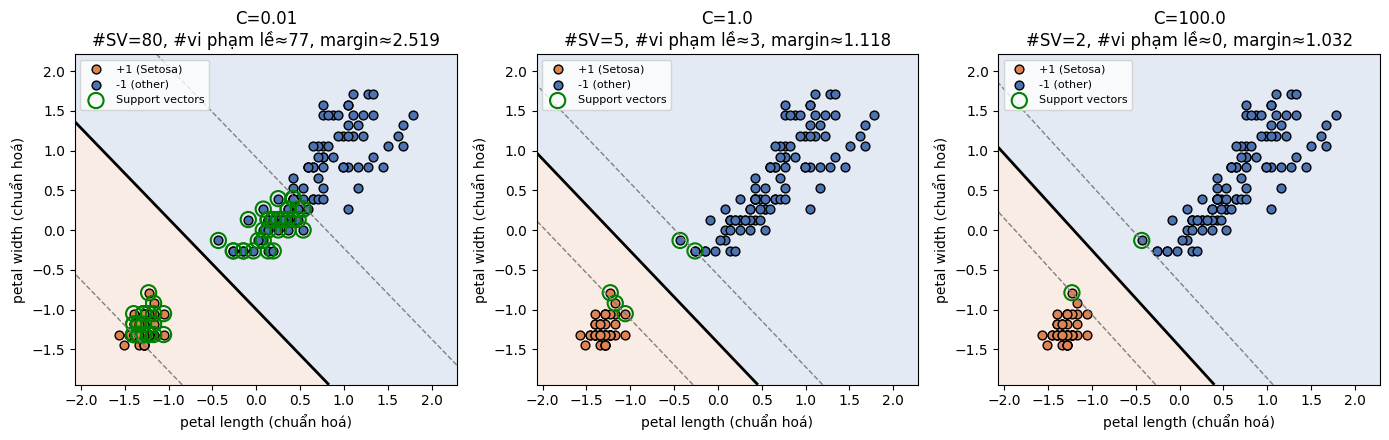

In [4]:
def plot_svm(clf, X, y, title, ax):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contour(xx, yy, Z, levels=[-1, 0, 1], linestyles=["--", "-", "--"],
               colors=["gray", "black", "gray"], linewidths=[1, 2, 1])
    ax.contourf(xx, yy, Z, levels=[-np.inf, 0, np.inf], alpha=0.15,
                colors=["#4C72B0", "#DD8452"])

    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="#DD8452", edgecolors="k",
               label="+1 (Setosa)", s=40)
    ax.scatter(X[y == -1, 0], X[y == -1, 1], c="#4C72B0", edgecolors="k",
               label="-1 (other)", s=40)

    sv = clf.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=120, facecolors="none",
               edgecolors="green", linewidths=1.5, label="Support vectors")

    ax.set_title(title)
    ax.set_xlabel("petal length (chuẩn hoá)")
    ax.set_ylabel("petal width (chuẩn hoá)")
    ax.legend(loc="best", fontsize=8)

Cs = [0.01, 1.0, 100.0]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

for ax, C in zip(axes, Cs):
    clf = SVC(kernel="linear", C=C)
    clf.fit(X, y)
    n_sv = len(clf.support_)
    decision = clf.decision_function(X)
    n_margin_viol = np.sum(y * decision < 1 - 1e-5)
    w_norm = np.linalg.norm(clf.coef_[0])
    margin = 2.0 / w_norm if w_norm > 0 else np.inf
    title = f"C={C}\n#SV={n_sv}, #vi phạm lề≈{n_margin_viol}, margin≈{margin:.3f}"
    plot_svm(clf, X, y, title, ax)
    print(f"C={C:6.2f} | #SV={n_sv:3d} | #vi phạm lề={n_margin_viol:3d} | ||w||={w_norm:.4f} | margin={margin:.4f}")

plt.tight_layout()
plt.show()

### Nhận xét ảnh hưởng của $C$

| $C$ | Lề | Số vi phạm lề | Ý nghĩa |
|-----|-----|---------------|--------|
| 0.01 | rộng | nhiều | Ưu tiên margin lớn, chấp nhận sai sót |
| 1 | trung bình | ít hơn | Cân bằng |
| 100 | hẹp hơn | rất ít / 0 | Ưu tiên phân loại đúng mọi điểm huấn luyện |

Trên Iris (Setosa vs rest) dữ liệu gần như tách tuyến tính hoàn toàn, nên khi $C$ lớn lề vẫn ổn định; khác biệt rõ hơn nếu dữ liệu nhiễu / chồng chéo.

---
## C5. Dữ liệu không khả tách tuyến tính (XOR) + bao lồi + ánh xạ đặc trưng

### Dữ liệu XOR 2D

$$
\begin{aligned}
x_1 &= (0,0),\; y_1 = -1 \\
x_2 &= (1,1),\; y_2 = -1 \\
x_3 &= (0,1),\; y_3 = +1 \\
x_4 &= (1,0),\; y_4 = +1
\end{aligned}
$$

### Chứng minh không tách được bằng bao lồi

Tập điểm lớp $+1$: $\{(0,1),(1,0)\}$.  
Bao lồi: đoạn thẳng nối hai điểm, chứa điểm giữa $(0.5, 0.5)$.

Tập điểm lớp $-1$: $\{(0,0),(1,1)\}$.  
Bao lồi: đoạn thẳng nối hai điểm, cũng chứa $(0.5, 0.5)$.

Hai bao lồi **giao nhau** tại $(0.5, 0.5)$ (và thực ra giao cả đoạn).  
Định lý tách siêu phẳng: hai tập lồi rời nhau trong $\mathbb{R}^d$ mới có thể tách bằng siêu phẳng.  
Vì bao lồi giao nhau → **không tồn tại siêu phẳng phân tách**.

### Ánh xạ đặc trưng làm dữ liệu khả tách

$$
\phi(x_1, x_2) = (x_1,\, x_2,\, x_1 x_2) \in \mathbb{R}^3
$$

(hoặc đơn giản hơn: $\phi = (x_1 x_2)$ một chiều — dấu của tích phân tách XOR).

Với $\phi(x) = x_1 x_2$:
- Lớp $-1$: $\phi(0,0)=0$, $\phi(1,1)=1$
- Lớp $+1$: $\phi(0,1)=0$, $\phi(1,0)=0$ — chưa tách.

Dùng $\phi(x) = (x_1, x_2, x_1 x_2)$: trong không gian 3D, mặt phẳng $z = 0.5$ (tức $x_1 x_2 = 0.5$) tách được hai lớp (điểm $(1,1,1)$ một phía, các điểm có tích 0 phía còn lại).

Kernel tương ứng: $k(x,x') = (x^\top x' + 1)^2$ (polynomial bậc 2) chứa hạng tử $x_1 x_2$.

Linear SVM accuracy trên XOR: 0.5
Poly-2 SVM accuracy trên XOR: 1.0


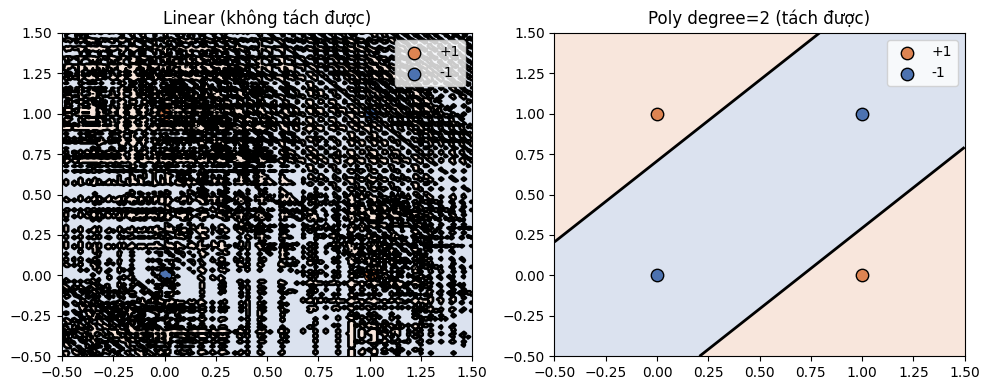

In [5]:
X_xor = np.array([[0, 0], [1, 1], [0, 1], [1, 0]], dtype=float)
y_xor = np.array([-1, -1, 1, 1])

clf_lin = SVC(kernel="linear", C=100)
clf_lin.fit(X_xor, y_xor)
print("Linear SVM accuracy trên XOR:", clf_lin.score(X_xor, y_xor))

clf_poly = SVC(kernel="poly", degree=2, C=100)
clf_poly.fit(X_xor, y_xor)
print("Poly-2 SVM accuracy trên XOR:", clf_poly.score(X_xor, y_xor))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, clf, title in zip(axes,
                          [clf_lin, clf_poly],
                          ["Linear (không tách được)", "Poly degree=2 (tách được)"]):
    xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
    Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-np.inf, 0, np.inf], alpha=0.2, colors=["#4C72B0", "#DD8452"])
    ax.contour(xx, yy, Z, levels=[0], colors="k", linewidths=2)
    ax.scatter(X_xor[y_xor == 1, 0], X_xor[y_xor == 1, 1], c="#DD8452", s=80, edgecolors="k", label="+1")
    ax.scatter(X_xor[y_xor == -1, 0], X_xor[y_xor == -1, 1], c="#4C72B0", s=80, edgecolors="k", label="-1")
    ax.set_title(title)
    ax.legend()
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(-0.5, 1.5)
plt.tight_layout()
plt.show()

---
## C6. Bài toán đối ngẫu SVM lề mềm cho dữ liệu C2

Với 2 điểm ở C2 (lề cứng tương đương $C \to \infty$, hoặc lề mềm với $\xi = 0$).

### Dạng gốc (primal, soft-margin)

$$
\begin{aligned}
\min_{w,b,\xi}\quad
&\frac12\|w\|^2 + C\sum_{n=1}^{2}\xi_n \\
\text{s.t.}\quad
& y_n(w^\top x_n + b) \ge 1 - \xi_n,\quad \xi_n \ge 0.
\end{aligned}
$$

### Dạng đối ngẫu

$$
\begin{aligned}
\max_{\alpha}\quad
&\sum_{n=1}^{2}\alpha_n - \frac12\sum_{n=1}^{2}\sum_{m=1}^{2}\alpha_n\alpha_m y_n y_m\, x_n^\top x_m \\
\text{s.t.}\quad
& 0 \le \alpha_n \le C,\quad \sum_{n=1}^{2}\alpha_n y_n = 0.
\end{aligned}
$$

**Quan sát:** dữ liệu $x_n$ **chỉ xuất hiện dưới dạng tích vô hướng** $x_n^\top x_m$.

### Vì sao cho phép dùng hàm nhân?

1. Mọi chỗ có $x_n^\top x_m$ có thể thay bằng $k(x_n, x_m) = \phi(x_n)^\top \phi(x_m)$ mà không cần tính $\phi$ tường minh.  
2. Nhờ đó SVM làm việc trong không gian đặc trưng rất cao (thậm chí vô hạn chiều) chỉ với chi phí tính kernel trên không gian gốc.

---
## Tóm tắt nhiệm vụ C

| Mục | Kết luận chính |
|-----|----------------|
| **C1** | petal length + petal width; Setosa = +1, rest = −1 |
| **C2** | $w^*=(1/2,1/2)$, $b^*=0$, margin $=2\sqrt{2}$, cả 2 điểm là SV |
| **C3** | $w$ → hướng + độ rộng lề; $b$ → dịch song song biên |
| **C4** | $C$ nhỏ → lề rộng, nhiều vi phạm; $C$ lớn → lề hẹp, ít vi phạm |
| **C5** | XOR: bao lồi giao nhau → không tách được; $\phi=(x_1,x_2,x_1x_2)$ tách được |
| **C6** | Đối ngẫu chỉ chứa $x_n^\top x_m$ → thay bằng kernel $k(x_n,x_m)$ |